# Solving the 1D Heat Equation in SageMath

We solve the heat (diffusion) PDE

$$ \frac{\partial u}{\partial t} = \alpha \frac{\partial^2 u}{\partial x^2}, \qquad 0 \le x \le L, \; t \ge 0 $$

with Dirichlet boundary conditions $u(0,t) = u(L,t) = 0$ and initial condition

$$ u(x,0) = f(x) = x(L - x). $$

This models, e.g., the temperature in a rod with ends held at 0, starting from a parabolic temperature profile.

## Method: separation of variables / Fourier sine series

The general solution satisfying the boundary conditions is

$$ u(x,t) = \sum_{n=1}^{\infty} b_n \sin\!\left(\frac{n\pi x}{L}\right) \exp\!\left(-\alpha \left(\frac{n\pi}{L}\right)^2 t\right), $$

where the Fourier sine coefficients are

$$ b_n = \frac{2}{L} \int_0^L f(x) \sin\!\left(\frac{n\pi x}{L}\right)\, dx. $$

We'll compute $b_n$ symbolically with Sage, then build a truncated series solution and plot it over time.

In [1]:
var('x t n')

L_val = 1.0       # rod length
alpha_val = 1.0   # thermal diffusivity
N = 20            # number of Fourier modes to sum

f(x) = x * (L_val - x)   # initial temperature profile
f

x |--> -(x - 1.00000000000000)*x

### Compute the Fourier sine coefficients $b_n$ symbolically

We use Sage's `integrate` to get a closed form for $b_n$, then evaluate it numerically for each mode.

In [2]:
b_n_expr = (2/L_val) * integrate(f(x) * sin(n*pi*x/L_val), x, 0, L_val)
b_n_expr = b_n_expr.simplify_full()
b_n_expr

(-2.0*pi*n*sin(1.0*pi*n) - 4.0*cos(1.0*pi*n) + 4.0)/(pi^3*n^3)

In [3]:
# Evaluate b_n numerically for n = 1..N
b_vals = [float(b_n_expr.subs(n=k).n()) for k in range(1, N+1)]
list(zip(range(1, N+1), b_vals))[:5]

[(1, 0.2580122754655959),
 (2, 1.0741918832168737e-17),
 (3, 0.009556010202429471),
 (4, 6.266119318765097e-18),
 (5, 0.0020640982037247626)]

### Build the truncated series solution $u(x,t)$

Using plain Python floats/math for speed, since we just need to evaluate the (already-computed) coefficients many times for plotting.

In [4]:
import math

def u_approx(xv, tv):
    s = 0.0
    for idx, k in enumerate(range(1, N+1)):
        s += b_vals[idx] * math.sin(k*math.pi*xv/L_val) * math.exp(-alpha_val*(k*math.pi/L_val)**2 * tv)
    return s

# Sanity check against the exact initial condition at t=0
print("u(0.5, 0)   ~", u_approx(0.5, 0.0), " vs f(0.5) =", f(0.5))
print("u(0.5, 0.1) ~", u_approx(0.5, 0.1))

u(0.5, 0)   ~ 0.249984108955900  vs f(0.5) = 0.250000000000000
u(0.5, 0.1) ~ 0.0961618714343480


### Plot the temperature profile at several times

As expected for the heat equation, the profile smooths out and decays toward zero (the steady state, since both ends are held at 0).

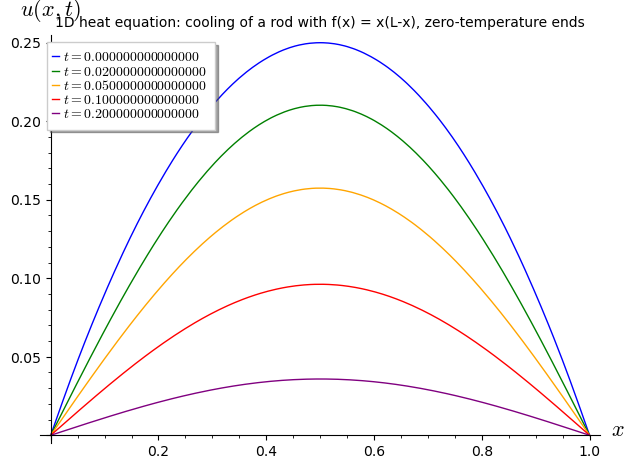

In [5]:
times = [0.0, 0.02, 0.05, 0.1, 0.2]
colors = ['blue', 'green', 'orange', 'red', 'purple']

p = sum(
    plot(lambda xv, tv=tv: u_approx(xv, tv), 0, L_val, color=c, legend_label=f'$t={tv}$')
    for tv, c in zip(times, colors)
)
p.axes_labels(['$x$', '$u(x,t)$'])
p.show(title="1D heat equation: cooling of a rod with f(x) = x(L-x), zero-temperature ends")

### 3D view of $u(x,t)$ over space and time

In [6]:
u_sage(x, t) = sum(
    b_vals[k-1] * sin(k*pi*x/L_val) * exp(-alpha_val*(k*pi/L_val)^2 * t)
    for k in range(1, N+1)
)
plot3d(u_sage, (x, 0, L_val), (t, 0, 0.3), color='red',
       mesh=True, title="u(x,t) surface")

Graphics3d Object